05 · EDA de clima: a chuva aumenta o delivery de comida?

A POF não tem data, então não dá para saber se choveu no dia de cada refeição. Este notebook busca evidência para a regra R3 do Decision Engine (score alto + em casa + chuva prevista → delivery) com o dataset Brazilian Delivery Center (Kaggle), pedidos de jan a abr/2021 em 4 cidades.

As duas bases não são juntadas: o Delivery Center serve só para testar o mecanismo "chuva → mais delivery" e não entra no modelo.

In [1]:
# importa bibliotecas
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# acha a pasta raiz do projeto (funciona rodando de notebooks/ ou da raiz)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# pastas dos dados
DC = ROOT / "data" / "raw" / "delivery_center"
EXT = ROOT / "data" / "external"

# cores e estilo dos gráficos
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e2",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelcolor": CINZA, "xtick.color": CINZA, "ytick.color": CINZA,
})
SEED = 42  # semente para reprodutibilidade

1. Carregar e juntar as tabelas do Delivery Center

- `orders`: um pedido por linha, com dia e hora;
- `stores`: a loja de cada pedido e o segmento (FOOD = comida, GOOD = produtos);
- `hubs`: o centro de distribuição de cada loja e a cidade.

In [2]:
# lê as três tabelas
orders = pd.read_csv(DC / "orders.csv", encoding="latin-1",
                     usecols=["order_id", "store_id", "order_status", "order_amount", "order_created_hour",
                              "order_created_day", "order_created_month", "order_created_year"])
stores = pd.read_csv(DC / "stores.csv", encoding="latin-1", usecols=["store_id", "hub_id", "store_segment"])  # loja → hub e segmento
hubs = pd.read_csv(DC / "hubs.csv", encoding="latin-1", usecols=["hub_id", "hub_city", "hub_state"])  # hub → cidade

# padroniza o nome da cidade (tira acento: "SÃO PAULO" -> "SAO PAULO")
hubs["cidade"] = (hubs["hub_city"].str.normalize("NFKD").str.encode("ascii", "ignore")
                  .str.decode("ascii").str.strip())

# junta pedidos → lojas → hubs
# validate garante que cada pedido encontra no máximo uma loja e um hub
ped = (orders.merge(stores, on="store_id", how="left", validate="many_to_one")
             .merge(hubs[["hub_id", "cidade"]], on="hub_id", how="left", validate="many_to_one"))
# monta a data do pedido
ped["data"] = pd.to_datetime(dict(year=ped.order_created_year, month=ped.order_created_month,
                                  day=ped.order_created_day))
# total de pedidos, período e contagem por cidade e segmento
print(f"{len(ped):,} pedidos | período: {ped.data.min().date()} a {ped.data.max().date()}")
print(ped["cidade"].value_counts())
print(ped["store_segment"].value_counts())

368,999 pedidos | período: 2021-01-01 a 2021-04-30
cidade
SAO PAULO         167590
RIO DE JANEIRO    137594
PORTO ALEGRE       34429
CURITIBA           29386
Name: count, dtype: int64
store_segment
FOOD    321775
GOOD     47224
Name: count, dtype: int64


2. Recorte: pedidos de comida, no horário do jantar

- FOOD: só lojas de comida;
- 18h às 22h: horário da ocasião de pizza;
- todos os pedidos criados, inclusive cancelados (mede a demanda).

Unidade da análise: cidade × dia.

In [3]:
noite = ped[(ped.store_segment == "FOOD") & ped.order_created_hour.between(18, 22)]  # comida entre 18h e 22h
# pedidos e % cancelados por cidade e dia
# cancelados = % de pedidos com status CANCELED
diario = noite.groupby(["cidade", "data"]).agg(pedidos=("order_id", "size"),
                                              cancelados=("order_status", lambda s: (s == "CANCELED").mean()))
print(diario.shape)
diario.head()

(480, 2)


pedidos  cancelados
cidade   data                           
CURITIBA 2021-01-01       11    0.727273
         2021-01-02       95    0.031579
         2021-01-03       89    0.033708
         2021-01-04       44    0.068182
         2021-01-05       60    0.033333

3. Clima e feriados

Coletados por `python -m src.coleta_clima` (em `data/external/`):
- Open-Meteo Archive: chuva (mm) e temperatura hora a hora em cada cidade;
- BrasilAPI: feriados nacionais de 2021.

Dia chuvoso: choveu ≥ 1 mm entre 12h e 22h.

In [4]:
# chuva e temperatura entre 12h e 22h, por cidade e dia
clima = pd.read_csv(EXT / "clima_horario_2021.csv", parse_dates=["momento"])
clima["data"] = clima["momento"].dt.normalize()  # tira a hora, fica só o dia
clima_dia = (clima[clima.momento.dt.hour.between(12, 22)]
             .groupby(["cidade", "data"]).agg(chuva_mm=("chuva_mm", "sum"), temperatura=("temperatura", "mean")))

feriados = pd.read_csv(EXT / "feriados_2021.csv", parse_dates=["date"])  # feriados nacionais

# junta clima e pedidos
dias = clima_dia.join(diario, how="inner").reset_index()
# 1 se choveu ≥ 1 mm
dias["chuvoso"] = (dias["chuva_mm"] >= 1).astype(int)
dias["dia_semana"] = dias["data"].dt.day_of_week          # 0 = segunda ... 6 = domingo
dias["semana"] = dias["data"].dt.isocalendar().week.astype(int)  # número da semana no ano
dias["feriado"] = dias["data"].isin(feriados["date"]).astype(int)  # 1 se a data é feriado
print(f"{len(dias)} cidade-dias | {dias.chuvoso.mean():.0%} chuvosos | {dias.feriado.sum()} cidade-dias de feriado")
dias.head()

480 cidade-dias | 43% chuvosos | 24 cidade-dias de feriado


,cidade,data,chuva_mm,temperatura,pedidos,cancelados,chuvoso,dia_semana,semana,feriado
0,CURITIBA,2021-01-01,2.8,19.945455,11,0.727273,1,4,53,1
1,CURITIBA,2021-01-02,4.6,19.000000,95,0.031579,1,5,53,0
2,CURITIBA,2021-01-03,1.8,17.972727,89,0.033708,1,6,53,0
3,CURITIBA,2021-01-04,1.2,20.354545,44,0.068182,1,0,1,0
4,CURITIBA,2021-01-05,9.5,22.972727,60,0.033333,1,1,1,0


4. Pedidos por dia e chuva (São Paulo)

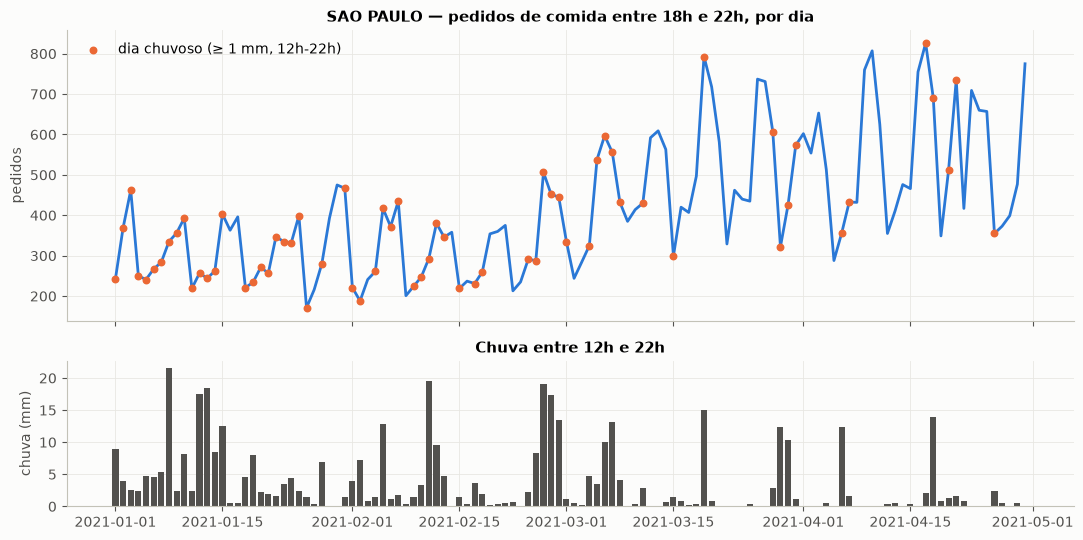

In [5]:
cid = "SAO PAULO"  # cidade do exemplo
# dias dessa cidade em ordem de data
d = dias[dias.cidade == cid].sort_values("data")
# pedidos por dia com os dias chuvosos marcados
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(d["data"], d["pedidos"], color=AZUL, lw=2)
# pontos laranja nos dias chuvosos
a1.scatter(d.loc[d.chuvoso == 1, "data"], d.loc[d.chuvoso == 1, "pedidos"], color=LARANJA, s=22, zorder=3,
           label="dia chuvoso (≥ 1 mm, 12h-22h)")
a1.set_title(f"{cid} — pedidos de comida entre 18h e 22h, por dia")
a1.set_ylabel("pedidos")
a1.legend(frameon=False, loc="upper left")
# chuva por dia
a2.bar(d["data"], d["chuva_mm"], color=CINZA, width=0.8)
a2.set_ylabel("chuva (mm)")
a2.set_title("Chuva entre 12h e 22h")
plt.tight_layout()
plt.show()

5. Comparação ingênua

In [6]:
# média de pedidos em dias secos × chuvosos, por cidade
ingenua = dias.groupby(["cidade", "chuvoso"])["pedidos"].mean().unstack()
# colunas 0 e 1 viram nomes
ingenua.columns = ["dia seco", "dia chuvoso"]
# quanto % o dia chuvoso tem a mais (ou a menos)
ingenua["diferença"] = ingenua["dia chuvoso"] / ingenua["dia seco"] - 1
ingenua.style.format({"dia seco": "{:.0f}", "dia chuvoso": "{:.0f}", "diferença": "{:+.0%}"})

,dia seco,dia chuvoso,diferença
cidade,,,
CURITIBA,122,80,-34%
PORTO ALEGRE,71,75,+5%
RIO DE JANEIRO,375,384,+3%
SAO PAULO,469,371,-21%


Essa comparação mistura efeitos de outros fatores (confundidores):
1. cidade;
2. dia da semana;
3. semana (crescimento da empresa e restrições da pandemia).

6. Comparação justa: mesma cidade, mesmo dia da semana, mesma semana

Regressão com efeitos fixos:

> log(pedidos) = efeito da chuva × chuvoso + efeito de (cidade × dia da semana) + efeito de (cidade × semana)

Intervalo de confiança de 95% por bootstrap (500 sorteios). Se o intervalo não cruza o zero, o efeito é estatisticamente diferente de zero.

In [7]:
def efeito_chuva(df, coluna_chuva="chuvoso", y="pedidos", log=True, n_boot=500):
    """Efeito (%) da chuva sobre y, com efeitos fixos cidade×dia-da-semana e cidade×semana."""
    # efeitos fixos como dummies
    fe = pd.get_dummies(pd.DataFrame({
        "cid_dow": df["cidade"] + "_" + df["dia_semana"].astype(str),
        "cid_sem": df["cidade"] + "_" + df["semana"].astype(str),
    }), drop_first=True).astype(float)
    X = np.column_stack([np.ones(len(df)), df[coluna_chuva].to_numpy(float), fe.to_numpy()])  # intercepto + chuva + efeitos fixos
    yv = np.log(df[y].to_numpy(float)) if log else df[y].to_numpy(float)  # log para o efeito sair em %
    coef = lambda idx: np.linalg.lstsq(X[idx], yv[idx], rcond=None)[0][1]  # coeficiente da chuva
    # sorteios do bootstrap
    rng = np.random.default_rng(SEED)
    todos = np.arange(len(df))
    # efeito usando todos os dias
    est = coef(todos)
    boot = [coef(rng.integers(0, len(df), len(df))) for _ in range(n_boot)]  # bootstrap: sorteia dias com reposição
    conv = (lambda b: np.expm1(b) * 100) if log else (lambda b: b * 100)  # log → % (expm1 = e^b − 1)
    # intervalo de 95%: percentis 2,5 e 97,5 dos sorteios
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"efeito_%": conv(est), "IC95_inf": conv(lo), "IC95_sup": conv(hi), "dias_chuvosos": int(df[coluna_chuva].sum())}


# testa chuva ≥ 1 mm e ≥ 5 mm, e o efeito nos cancelados
resultados = {}
for lim in [1, 5]:
    # coluna 1/0 para cada limite de chuva
    dias[f"chuva_{lim}mm"] = (dias["chuva_mm"] >= lim).astype(int)
    resultados[f"pedidos | chuva ≥ {lim} mm"] = efeito_chuva(dias, f"chuva_{lim}mm")
# cancelados já é %, então sem log
resultados["% cancelados | chuva ≥ 1 mm"] = efeito_chuva(dias, "chuva_1mm", y="cancelados", log=False)
# tabela com efeito e intervalo de cada teste
res = pd.DataFrame(resultados).T
res.style.format({"efeito_%": "{:+.1f}%", "IC95_inf": "{:+.1f}%", "IC95_sup": "{:+.1f}%", "dias_chuvosos": "{:.0f}"})

,efeito_%,IC95_inf,IC95_sup,dias_chuvosos
pedidos | chuva ≥ 1 mm,+5.7%,+1.1%,+10.7%,206
pedidos | chuva ≥ 5 mm,+6.1%,-0.1%,+12.4%,70
% cancelados | chuva ≥ 1 mm,-0.2%,-0.8%,+0.5%,206


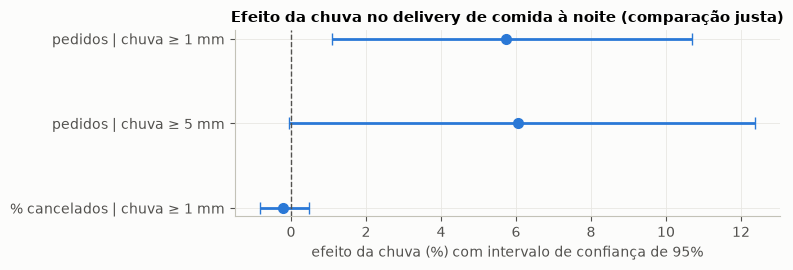

In [8]:
# efeito da chuva com intervalo de confiança de 95%
fig, ax = plt.subplots(figsize=(8, 2.8))
# inverte a ordem para o primeiro teste ficar em cima
r = res.iloc[::-1]
y = np.arange(len(r))
# ponto = efeito | barra = intervalo de confiança
ax.errorbar(r["efeito_%"], y, xerr=[r["efeito_%"] - r["IC95_inf"], r["IC95_sup"] - r["efeito_%"]],
            fmt="o", color=AZUL, ecolor=AZUL, elinewidth=2, capsize=4, ms=7)
# linha do zero: se a barra cruza, o efeito pode ser acaso
ax.axvline(0, color=CINZA, lw=1, ls="--")
ax.set_yticks(y, r.index)
ax.set_xlabel("efeito da chuva (%) com intervalo de confiança de 95%")
ax.set_title("Efeito da chuva no delivery de comida à noite (comparação justa)")
plt.tight_layout()
plt.show()

7. Chuva na hora

Testa no nível da hora: está chovendo às 20h → mais pedidos às 20h?

In [9]:
# pedidos por cidade e hora
hora = noite.assign(momento=lambda x: x["data"] + pd.to_timedelta(x["order_created_hour"], unit="h"))
por_hora = hora.groupby(["cidade", "momento"]).size().rename("pedidos")
# junta com a chuva das 18h às 22h
h = (clima[clima.momento.dt.hour.between(18, 22)].set_index(["cidade", "momento"])
     .join(por_hora).fillna({"pedidos": 0}).reset_index())
# 1 se choveu ≥ 0,5 mm naquela hora
h["chovendo"] = (h["chuva_mm"] >= 0.5).astype(int)
h["dia_semana"] = h["momento"].dt.day_of_week
h["semana"] = h["momento"].dt.isocalendar().week.astype(int)
h["pedidos"] = h["pedidos"] + 1  # +1 para o log funcionar em horas sem pedido
# efeito fixo extra: hora (19h é diferente de 22h)
h["dia_semana"] = h["dia_semana"].astype(str) + "_" + h["momento"].dt.hour.astype(str)
# mesmo cálculo da seção 6, agora por hora (200 sorteios)
pd.DataFrame({"pedidos | chovendo naquela hora": efeito_chuva(h, "chovendo", n_boot=200)}).T.style.format(
    {"efeito_%": "{:+.1f}%", "IC95_inf": "{:+.1f}%", "IC95_sup": "{:+.1f}%"})

,efeito_%,IC95_inf,IC95_sup,dias_chuvosos
pedidos | chovendo naquela hora,-1.4%,-6.5%,+5.3%,178.000000


8. Feriados

Poucos feriados no período, então a análise é só descritiva.

In [10]:
# pedidos no feriado × média do mesmo dia da semana
dias["dia_nome"] = dias["data"].dt.day_name()  # nome do dia da semana
fer = dias[dias.feriado == 1][["cidade", "data", "dia_nome", "pedidos", "chuva_mm"]]
# média de pedidos de cada cidade e dia da semana, sem feriados
media_dow = dias[dias.feriado == 0].groupby(["cidade", "dia_semana"])["pedidos"].mean()
fer["media_mesmo_dia_semana"] = [media_dow.get((c, d.day_of_week)) for c, d in zip(fer.cidade, fer.data)]
# quanto o feriado ficou acima ou abaixo do normal
fer["vs_media"] = fer["pedidos"] / fer["media_mesmo_dia_semana"] - 1
fer.sort_values(["data", "cidade"]).style.format({"vs_media": "{:+.0%}", "media_mesmo_dia_semana": "{:.0f}", "chuva_mm": "{:.1f}"})

,cidade,data,dia_nome,pedidos,chuva_mm,media_mesmo_dia_semana,vs_media
0,CURITIBA,2021-01-01 00:00:00,Friday,11,2.8,94,-88%
120,PORTO ALEGRE,2021-01-01 00:00:00,Friday,48,0.0,97,-50%
240,RIO DE JANEIRO,2021-01-01 00:00:00,Friday,192,3.8,414,-54%
360,SAO PAULO,2021-01-01 00:00:00,Friday,243,9.0,550,-56%
45,CURITIBA,2021-02-15 00:00:00,Monday,71,1.7,77,-8%
165,PORTO ALEGRE,2021-02-15 00:00:00,Monday,61,2.6,61,-0%
285,RIO DE JANEIRO,2021-02-15 00:00:00,Monday,333,0.3,295,+13%
405,SAO PAULO,2021-02-15 00:00:00,Monday,219,1.5,299,-27%
46,CURITIBA,2021-02-16 00:00:00,Tuesday,92,1.4,78,+18%
166,PORTO ALEGRE,2021-02-16 00:00:00,Tuesday,63,0.5,68,-7%
